In [3]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

In [9]:
def synthetic_data(w,b,num_examples):
    X=torch.normal(0,1,(num_examples,len(w)))
    Y=torch.mv(X,w)+b
    Y+=torch.normal(0,0.01,Y.shape)
    return X,Y.reshape(-1,1)

In [11]:
true_w = torch.tensor([2,-3.4])
true_b = 4.2
features,labels = synthetic_data(true_w,true_b,1000)

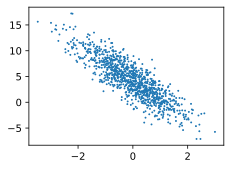

In [13]:
d2l.set_figsize()
d2l.plt.scatter(features[:,(1)].detach().numpy(), labels.detach().numpy(),1)

In [17]:
def data_iter(batch_size, features, labels):
    num_examples = features.shape[0]
    indices = list(range(num_examples))
    random.shuffle(indices)
    for i in range(0,num_examples,batch_size):
        batch_indices = indices[i:min(i+batch_size,num_examples)]
        yield features[batch_indices], labels[batch_indices]

In [37]:
def linearReg(X,w,b):
    return torch.mm(X,w)+b

In [38]:
def squared_loss(y_hat,y):
    return (y_hat-y.reshape(y.shape))**2/2

In [39]:
def sgl(params,lr,batch_size):
    with torch.no_grad():
        for param in params:
            param -= param.grad * lr / batch_size
            param.grad.zero_()
    return params

In [53]:
batch_size = 20
net = linearReg
loss = squared_loss
num_epochs=4
lr = 0.03
w = torch.normal(0,0.01,size=(2,1),requires_grad=True)
b = torch.zeros(1,requires_grad=True)

for epoch in range(num_epochs):
    for fe,la in data_iter(batch_size,features,labels):
        l = loss(net(fe,w,b),la)
        l.sum().backward()
        sgl([w,b],lr,batch_size)
    with torch.no_grad():
        losses = loss(net(features,w,b),labels)
        print(f"epoch{epoch}，loss:{losses.mean():.4f}")

print(f"true loss of W:{abs(true_w-w.reshape(true_w.shape))}\ntrue loss of b:{abs(true_b-b)}\n")

epoch0，loss:0.7233
epoch1，loss:0.0309
epoch2，loss:0.0014
epoch3，loss:0.0001
true loss of W:tensor([0.0059, 0.0043], grad_fn=<AbsBackward0>)
true loss of b:tensor([0.0084], grad_fn=<AbsBackward0>)

